# Exercise 3: cleaning data

The daily weather of 2023 at 13 KMI stations, `../../data/raw/kmi_daily_2023.csv`, as in exercise 1.

In [1]:
import pandas as pd

**3.1** Read the file. Before you analyze it, check it: does every station have a full year of days? Are
there rows that occur twice, or several rows for the same station and day?

In [2]:
daily = pd.read_csv("../../data/raw/kmi_daily_2023.csv")
daily["name"].value_counts()

name
BEITEM                  365
ZEEBRUGGE               365
MELLE                   365
STABROEK                365
SINT-KATELIJNE-WAVER    365
UCCLE                   365
DOURBES                 365
ERNAGE                  365
RETIE                   365
HUMAIN                  365
DIEPENBEEK              365
BUZENOL                 365
MONT RIGI               365
Name: count, dtype: int64

In [3]:
daily.duplicated().sum()

np.int64(0)

In [4]:
daily.duplicated(subset=["name", "timestamp"]).sum()

np.int64(0)

Every station has 365 days, and there are no duplicates: the KMI data is complete.

**3.2** Add a column with the temperature range of every day: the highest minus the lowest temperature.
Keep the DataFrame you read unchanged. What is the mean range at Zeebrugge, on the coast, and at Uccle, in
Brussels?

In [5]:
with_range = daily.assign(temp_range=daily["temp_max"] - daily["temp_min"])
with_range

,name,timestamp,temp_min,temp_avg,temp_max,precip_quantity,sun_duration,wind_gusts_speed,temp_range
0,BEITEM,2023-01-01,10.69,12.11,14.43,2.67,18.83,16.30,3.74
1,BEITEM,2023-01-02,3.62,8.54,13.16,0.80,86.58,12.68,9.54
2,BEITEM,2023-01-03,2.45,7.53,9.96,1.99,279.75,15.36,7.51
3,BEITEM,2023-01-04,9.99,11.67,13.27,2.19,0.00,15.71,3.28
4,BEITEM,2023-01-05,9.60,10.79,12.32,1.70,43.67,9.78,2.72
...,...,...,...,...,...,...,...,...,...
4740,MONT RIGI,2023-12-27,1.47,3.88,4.94,0.90,0.00,13.18,3.47
4741,MONT RIGI,2023-12-28,3.94,5.23,6.30,1.30,13.50,15.15,2.36
4742,MONT RIGI,2023-12-29,4.60,5.45,5.89,7.10,0.00,17.29,1.29
4743,MONT RIGI,2023-12-30,3.60,4.60,5.55,0.20,7.50,14.96,1.95


In [6]:
with_range[with_range["name"] == "ZEEBRUGGE"]["temp_range"].mean()

np.float64(4.247397260273973)

In [7]:
with_range[with_range["name"] == "UCCLE"]["temp_range"].mean()

np.float64(7.2354520547945205)

At the coast, the difference between night and day is about 4 °C, in Brussels about 7 °C. The sea warms
up and cools down slowly, so it keeps the nights mild and the days cool.

**3.3** Label every day as cold (mean temperature below 10 °C), mild (below 20 °C) or warm. How many days
of each did Uccle and Zeebrugge have? Plot the counts of Uccle as a bar chart (`kind="bar"`).

In [8]:
labelled = daily.assign(
    kind=daily["temp_avg"].case_when([
        (daily["temp_avg"] < 10, "cold"),
        (daily["temp_avg"] < 20, "mild"),
        (daily["temp_avg"] >= 20, "warm"),
    ])
)
labelled

,name,timestamp,temp_min,temp_avg,temp_max,precip_quantity,sun_duration,wind_gusts_speed,kind
0,BEITEM,2023-01-01,10.69,12.11,14.43,2.67,18.83,16.30,mild
1,BEITEM,2023-01-02,3.62,8.54,13.16,0.80,86.58,12.68,cold
2,BEITEM,2023-01-03,2.45,7.53,9.96,1.99,279.75,15.36,cold
3,BEITEM,2023-01-04,9.99,11.67,13.27,2.19,0.00,15.71,mild
4,BEITEM,2023-01-05,9.60,10.79,12.32,1.70,43.67,9.78,mild
...,...,...,...,...,...,...,...,...,...
4740,MONT RIGI,2023-12-27,1.47,3.88,4.94,0.90,0.00,13.18,cold
4741,MONT RIGI,2023-12-28,3.94,5.23,6.30,1.30,13.50,15.15,cold
4742,MONT RIGI,2023-12-29,4.60,5.45,5.89,7.10,0.00,17.29,cold
4743,MONT RIGI,2023-12-30,3.60,4.60,5.55,0.20,7.50,14.96,cold


In [9]:
labelled[labelled["name"] == "UCCLE"]["kind"].value_counts()

kind
mild    172
cold    150
warm     43
Name: count, dtype: int64

In [10]:
labelled[labelled["name"] == "ZEEBRUGGE"]["kind"].value_counts()

kind
mild    209
cold    133
warm     23
Name: count, dtype: int64

<Axes: xlabel='kind'>

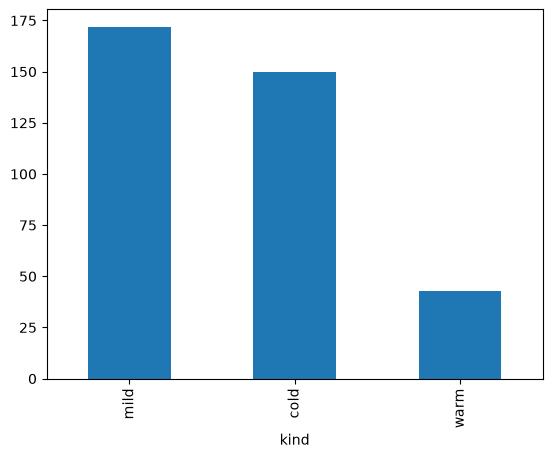

In [11]:
labelled[labelled["name"] == "UCCLE"]["kind"].value_counts().plot(kind="bar")

The coast has fewer cold days and fewer warm days: the sea keeps the temperature in between.

## Bonus

Do 3.2 again as one method chain with `pd.col`, starting from `pd.read_csv`: read the file, add the
temperature range, keep only Zeebrugge, and compute the mean range.

In [12]:
(
    pd.read_csv("../../data/raw/kmi_daily_2023.csv")
    .assign(temp_range=pd.col("temp_max") - pd.col("temp_min"))
    [pd.col("name") == "ZEEBRUGGE"]
    ["temp_range"]
    .mean()
)

np.float64(4.247397260273973)